# Custom error modelling in post-processing

Notebook: Vincent Verhoeven and Hannah Weiser, 2026

HELIOS++ supports modelling of simple Gaussian noise on the distance measurements via the accuracy parameter in the scanner definition. This notebook demonstrates how more complex, custom error models can be implemented as a post-processing step. For this, we first simulate noise-free scans with HELIOS++, using a custom scanner definition, and then add distance-dependent Gaussian noise and further filter by a maximum incidence angle.

In [9]:
import numpy as np
import helios
from helios import units
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=456902374302593480495)
helios.add_asset_directory("../data")

Here, we define two functions for modelling the error as well as for filtering by incidence angle. The `pc` that they take as input are the measurement NumPy arrays as returned by the HELIOS++ Python API.

In [10]:
def add_scan_noise(pc,
                   rng,
                   beam_divergence,
                   beam_exit_diameter,
                   sigma_range_0,
                   range_bias,
                   ):
    """
    This function takes the helios output NumPy array
    (that includes position, beam_origin, beam_direction, distance and incidence_angle [rad]),
    adds the distance- and incidence-angle-dependent Gaussian noise.
    """
    distance = pc["distance"]

    # range uncertainty
    beam_width = beam_exit_diameter + 2 * distance * np.tan(beam_divergence)
    sigma_radial = beam_width / 4  # as the beamwidth is defined to be 4 standard deviations, i.e., 2 in each direction
    sigma_range = sigma_range_0 + sigma_radial * np.tan(pc["incidence_angle"])

    # resulting range noise
    sn_noise = rng.standard_normal(len(pc))
    range_noise = range_bias + sigma_range * sn_noise

    # noise distances
    distances_noisy = distance + range_noise

    # noisy point locations
    points_noisy = pc["beam_origin"] + pc["beam_direction"] * distances_noisy[:, None]
    pc_noisy = pc.copy()
    pc_noisy["position"] = points_noisy
    pc_noisy["distance"] = distances_noisy

    return pc_noisy


def filter_by_incidence_angle(pc, max_incidence_angle):
    """
    This functions takes the helios output NumPy array (that includes incidence_angle),
    and filters it by incidence angle.
    indicence_angle is assumed to be in [rad]
    """
    # remove points exceeding the maximum incidence angle
    filter_idx = pc["incidence_angle"] < max_incidence_angle
    pc_noisy_filtered = pc[filter_idx]

    return pc_noisy_filtered, filter_idx

We load a custom scanner that has accuracy set to zero so the simulated ranges are noise-free. We will use a simple tripod to mount it to.

In [11]:
my_scanner_file = "test/test_scanners.xml"
scanner = helios.Scanner.from_xml(my_scanner_file, scanner_id="riegl_vz400_adj")
platform = helios.platform_from_name("tripod")

For demonstration, we are using the arbaro tree scene for the simulation.

In [12]:
# load objs and create transformations
groundplane = helios.ScenePart.from_obj(
    "sceneparts/basic/groundplane/groundplane.obj",
).scale(
    100
)
tree1 = helios.ScenePart.from_obj(
    "sceneparts/arbaro/black_tupelo_low.obj", up_axis="y"
)  # 3D models exported from Blender often have the Y-axis as "up-axis"
tree2 = helios.ScenePart.from_obj(
    "sceneparts/arbaro/sassafras_low.obj", up_axis="y"
)
# Trees should both be scaled down by half and translated
tree1 = tree1.scale(0.5).translate([0.0, 15.0, 0.0])
tree2 = tree2.scale(0.5).translate([-10.0, 15.0, 0.0])

scene = helios.StaticScene(scene_parts=[groundplane, tree1, tree2])

Next, we define the scanner settings, create the survey and add a single scan position.

In [13]:
scanner_settings = helios.ScannerSettings(
    pulse_frequency=100_000 * units.Hz,
    vertical_resolution=0.04 * units.deg,
    horizontal_resolution=0.04 * units.deg,
    min_vertical_angle=-40 * units.deg,
    max_vertical_angle=60 * units.deg,
)

survey = helios.Survey(
    scanner=scanner,
    platform=platform,
    scene=scene,
)

survey.add_leg(
    scanner_settings=scanner_settings,
    x=1.0,
    y=25.5,
    force_on_ground=True,
    rotation_start_angle=100 * units.deg,
    rotation_stop_angle=225 * units.deg,
)

Finally, we can execute the survey.

In [14]:
points, trajectories = survey.run(
    verbosity=helios.LogVerbosity.VERBOSE, format=helios.OutputFormat.NPY
)

Legs:   0%|          | 0/1 [00:00<?, ?leg/s]

Current leg time: 0.00s [00:00, ?s/s]

This is the step where we add the noise to our noise-free point cloud and filter out high-incidence angle points. The range standard deviation is the instrument noise plus a term from the beam footprint. The footprint is projected onto the surface and stretched along the beam by `tan(incidence_angle)`, so noise grows with distance and with incidence angle.

- `sigma_r0` is the constant range noise of the instrument at zero beam width, in m.
- `beam_div` is the (half-angle) beam divergence in rad.
- `beam_exit_diameter` is the beam diameter at the scanner exit in m. It is 0 here.
- `range_bias` is a constant systematic offset on the range in m. It is 0 here.

We also remove grazing points with incidence angle above a threshold `max_inc_angle` (prior to noise addition).

Only `position` and `distance` are updated in the noisy point cloud. Other fields, such as `incidence_angle` keep their noise-free values.

In [15]:
beam_div = 0.0003   # beam divergence [rad]
sigma_r0 = 0.003    # range uncertainty of the instrument [m]
max_inc_angle = 80  # deg

points_filtered, _ = filter_by_incidence_angle(points,
                                               max_incidence_angle=np.deg2rad(max_inc_angle)  # [rad]
                                               )

points_noisy_filtered = add_scan_noise(
    points_filtered,
    rng=rng,
    beam_divergence=beam_div,
    beam_exit_diameter=0.0,
    sigma_range_0=sigma_r0,
    range_bias=0.0
)

Finally, we plot the noise-free and noisy point clouds overlaid and side-by-side. We clip out a smaller area so we can actually compare the points.

Point cloud w/o noise:		4588086 points
Subset w/o noise:		1304 points

Point cloud with noise:		3806040 points
Subset with noise:		1220 points



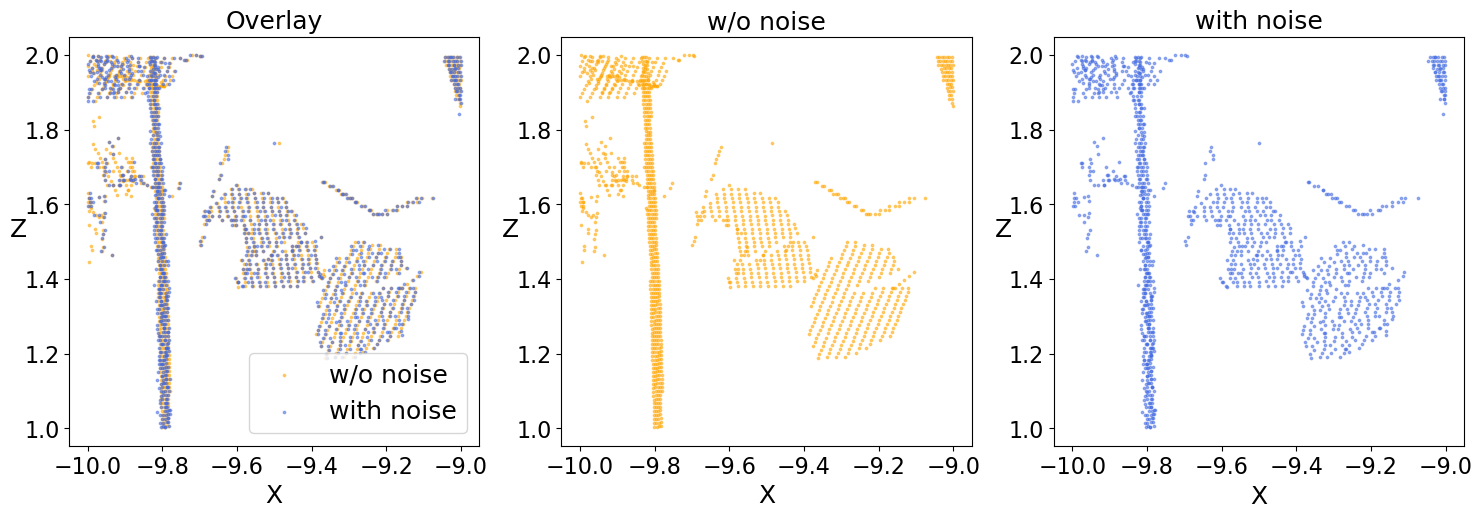

In [18]:
def bbox_mask(pts, xmin, xmax, ymin, ymax, zmin, zmax):
    pos = pts["position"]
    clip_index = (
        (pos[:, 0] > xmin)
        & (pos[:, 0] < xmax)
        & (pos[:, 1] > ymin)
        & (pos[:, 1] < ymax)
        & (pos[:, 2] > zmin)
        & (pos[:, 2] < zmax)
    )
    return clip_index

bbox = (-10, -9, 10, 15, 1, 2)  # xmin, xmax, ymin, ymax, zmin, zmax
colors = ["orange", "royalblue"]
labels = ["w/o noise", "with noise"]
titles = [
    "Overlay",
    labels[0],
    f"{labels[1]}"
]

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

for i, pc in enumerate([points, points_noisy_filtered]):
    print(f"Point cloud {labels[i]}:\t\t{len(pc)} points")
    pos = pc[bbox_mask(pc, *bbox)]["position"]
    print(f"Subset {labels[i]}:\t\t{len(pos)} points\n")
    axs[0].scatter(pos[:, 0], pos[:, 2], s=3, alpha=0.5, c=colors[i], label=labels[i])
    axs[i+1].scatter(pos[:, 0], pos[:, 2], s=3, alpha=0.5, c=colors[i])

axs[0].legend(fontsize=18)
for ax, title in zip(axs, titles):
    ax.set_aspect("equal")
    ax.tick_params(labelsize=16)
    ax.set_xlabel("X", fontsize=18)
    ax.set_ylabel("Z", fontsize=18, rotation=0)
    ax.set_title(title, fontsize=18)
plt.show()